In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import mean_squared_error
from sklearn.cluster import KMeans
import statsmodels.api as sm
import warnings
warnings.filterwarnings("ignore")

In [22]:
dat_satact = pd.read_csv("SAT and ACT Cleaned.csv")
char = pd.read_csv("School Characteristics Cleaned.csv")
enr = pd.read_csv('enrollment_cleaned.csv')

In [23]:
enr = enr.dropna(axis = 1, how = 'all')
enr = enr.loc[enr['Combokey'].isin(dat_satact['Combokey'])]
enr = enr.add_prefix('TOT ')
enr.rename(columns={'TOT Combokey': 'Combokey'}, inplace=True)
enr.iloc[:, 3:]

,Combokey,TOT Hispanic Male,TOT Hispanic Female,TOT Native American Male,TOT Native American Female,TOT Asian Male,TOT Asian Female,TOT Pacific Islander Male,TOT Pacific Islander Female,TOT Black Male,...,TOT EL Male,TOT EL Female,TOT IDEA Male,TOT IDEA Female,TOT 504 Male,TOT 504 Female,TOT Total Males,TOT Total Females,TOT IDEA Males,TOT IDEA Females
4970,60000310347,107.0,57.0,0.0,0.0,14.0,18.0,1.0,1.0,10.0,...,0.0,0.0,171.0,123.0,NaN,NaN,171.0,123.0,171.0,123.0
4978,60000908779,25.0,22.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,7.0,1.0,NaN,NaN,34.0,25.0,7.0,1.0
4986,60001302405,165.0,157.0,3.0,5.0,141.0,125.0,4.0,5.0,13.0,...,35.0,30.0,148.0,78.0,53.0,27.0,1029.0,945.0,148.0,78.0
4999,60001311010,183.0,171.0,10.0,2.0,145.0,172.0,6.0,3.0,24.0,...,21.0,25.0,154.0,72.0,67.0,56.0,1021.0,959.0,154.0,72.0
5008,60001409072,993.0,902.0,3.0,1.0,19.0,8.0,2.0,3.0,84.0,...,298.0,232.0,245.0,133.0,13.0,7.0,1227.0,1094.0,245.0,133.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87231,484668011982,129.0,165.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,...,16.0,29.0,3.0,9.0,13.0,18.0,133.0,174.0,3.0,9.0
87241,484668022828,80.0,48.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,34.0,23.0,10.0,5.0,14.0,10.0,82.0,49.0,10.0,5.0
87243,484671005351,570.0,491.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,...,213.0,189.0,120.0,50.0,103.0,63.0,572.0,496.0,120.0,50.0
87249,484674005354,5.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,20.0,7.0,14.0,4.0,89.0,69.0,20.0,7.0


In [44]:
dat = pd.merge(pd.merge(dat_satact, char, on = 'Combokey', how = 'inner'), enr.iloc[:, 3:], on = 'Combokey', how = 'inner')

In [45]:
prop_total = (dat['TOT Total Males'] + dat['TOT Total Females'])/dat['Total']

In [46]:
def prop(var1, var2) :
    return var1/var2

In [47]:
prop

<function __main__.prop(var1, var2)>

In [48]:
dat_ca = dat.loc[(dat['State'] == 'CA')]

In [49]:
def prop(var1, var2) :
    return var1/var2

In [50]:
dat_ca['Justice Facility'] = dat_ca['Justice Facility'].map({'No': 0, 'Yes': 1})
dat_ca['Fully Virtual'] = dat_ca['Fully Virtual'].map({'No' : 0, 'Yes' : 1})
dat_ca['Ungraded'] = dat_ca['Ungraded'].map({'No' : 0, 'Yes' : 1})
dat_ca['Special Education'] = dat_ca['Special Education'].map({'No' : 0, 'Yes' : 1})
dat_ca['Magnet School/Program'] = dat_ca['Magnet School/Program'].map({'No' : 0, 'Yes' : 1})
dat_ca['Charter School'] = dat_ca['Charter School'].map({'No' : 0, 'Yes' : 1})
dat_ca['Alternative School'] = dat_ca['Alternative School'].map({'No' : 0, 'Yes' : 1})

In [55]:
outcome = ['Total']
features = [ 'Fully Virtual', 'Ungraded',
       'Special Education', 'Magnet School/Program', 'Charter School',
       'Alternative School', 'TOT Hispanic Male', 'TOT Hispanic Female',
       'TOT Native American Male', 'TOT Native American Female',
       'TOT Asian Male', 'TOT Asian Female', 'TOT Pacific Islander Male',
       'TOT Pacific Islander Female', 'TOT Black Male', 'TOT Black Female',
       'TOT White Male', 'TOT White Female', 'TOT Two or more races Male',
       'TOT Two or more races Female', 'TOT EL Male', 'TOT EL Female',
       'TOT IDEA Male', 'TOT IDEA Female', 'TOT 504 Male', 'TOT 504 Female',
       'TOT Total Males', 'TOT Total Females', 'TOT IDEA Males',
       'TOT IDEA Females']

In [59]:
# Select and clean the data by dropping any rows with missing values
model_data = dat_ca[features + outcome].dropna()

X_ca = model_data[features]
y_ca = model_data[outcome]

X_ca = sm.add_constant(X_ca)

model = sm.OLS(y_ca, X_ca).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Total   R-squared:                       0.314
Model:                            OLS   Adj. R-squared:                  0.295
Method:                 Least Squares   F-statistic:                     16.51
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           4.51e-60
Time:                        21:49:40   Log-Likelihood:                -6073.6
No. Observations:                 967   AIC:                         1.220e+04
Df Residuals:                     940   BIC:                         1.233e+04
Df Model:                          26                                         
Covariance Type:            nonrobust                                         
================================================================================================
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                           49.4999     10.023      4.938      0.000      29.829      69.171
Fully Virtual                  -35.1450     25.982     -1.353      0.176     -86.134      15.844
Ungraded                       -50.8931     25.698     -1.980      0.048    -101.326      -0.460
Special Education              -63.1607     47.257     -1.337      0.182    -155.902      29.581
Magnet School/Program          -29.5966     17.747     -1.668      0.096     -64.425       5.232
Charter School                 -30.7830     13.233     -2.326      0.020     -56.753      -4.813
Alternative School             -38.7792     26.501     -1.463      0.144     -90.787      13.228
TOT Hispanic Male                0.5056      0.312      1.618      0.106      -0.108       1.119
TOT Hispanic Female              0.4512      0.339      1.333      0.183      -0.213       1.116
TOT Native American Male        -1.2090      1.481     -0.816      0.415      -4.116       1.698
TOT Native American Female      -1.3163      1.595     -0.825      0.409      -4.446       1.814
TOT Asian Male                   0.5028      0.344      1.463      0.144      -0.172       1.177
TOT Asian Female                 0.5630      0.369      1.527      0.127      -0.161       1.287
TOT Pacific Islander Male       -1.8761      1.328     -1.413      0.158      -4.483       0.731
TOT Pacific Islander Female     -0.9042      1.402     -0.645      0.519      -3.656       1.848
TOT Black Male                   1.2710      0.455      2.791      0.005       0.377       2.165
TOT Black Female                 0.0676      0.454      0.149      0.882      -0.823       0.958
TOT White Male                   0.5980      0.346      1.726      0.085      -0.082       1.278
TOT White Female                 0.1899      0.378      0.503      0.615      -0.551       0.931
TOT Two or more races Male      -0.0307      0.414     -0.074      0.941      -0.843       0.782
TOT Two or more races Female     0.4400      0.454      0.968      0.333      -0.452       1.332
TOT EL Male                     -0.2453      0.268     -0.916      0.360      -0.771       0.280
TOT EL Female                   -0.1899      0.332     -0.573      0.567      -0.841       0.461
TOT IDEA Male                   -0.2656      0.124     -2.142      0.032      -0.509      -0.022
TOT IDEA Female                  0.0850      0.187      0.454      0.650      -0.282       0.452
TOT 504 Male                    -0.9541      0.505     -1.888      0.059      -1.946       0.037
TOT 504 Female                   2.5946      0.473      5.486      0.000       1.666       3.523
TOT Total Males                 -0.2383      0.295     -0.808      0.420      -0.818       0.341
TOT Total Females               -0.5088      0.318     -1.601      0.110    

# Random Forests

In [70]:
X_train_ca, X_test_ca, y_train_ca, y_test_ca = train_test_split(X_ca, y_ca, test_size=0.2)

In [75]:
regressor = DecisionTreeRegressor(max_depth=4)

In [76]:
regressor.fit(X_train_ca, y_train_ca)

DecisionTreeRegressor(max_depth=4)

In [77]:
y_pred_ca = regressor.predict(X_test_ca)

mse = mean_squared_error(y_test_ca, y_pred_ca)
print(f"Mean Squared Error: {mse:.4f}")

Mean Squared Error: 21675.5928


In [81]:
np.sqrt(mse)

np.float64(147.22633192322073)

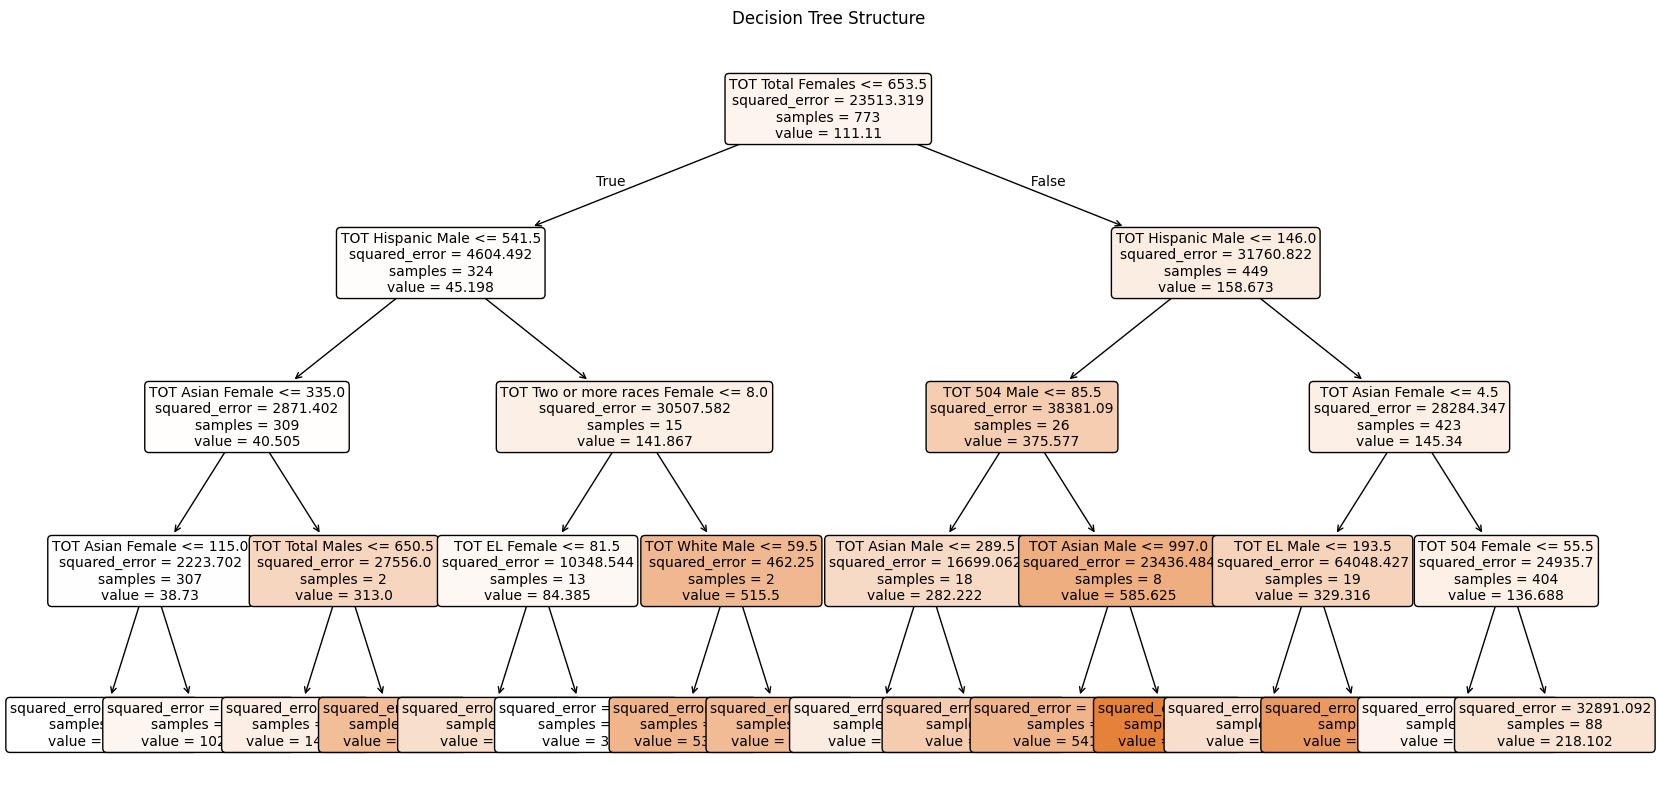

In [79]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    regressor,
    feature_names=list(X_train_ca.columns),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure")
plt.show()

In [80]:
np.mean(dat_ca['TOT Total Females'] + dat_ca['TOT Total Males'])

np.float64(1396.3058933582788)

In [87]:
np.sqrt(mse)/(np.max(dat_ca['Total']) - np.min(dat_ca['Total']))

np.float64(0.11892272368596181)

In [85]:
np.min(dat_ca['Total'])

2